# Proyecto Data Science – Parte III
**Alumno:** Massironi  
**Dataset:** Marketing Campaign Dataset (`Defaultoutput.xlsx`)  
**Fecha:** Julio 2026

---
## Introducción

Esta entrega complementa el análisis exploratorio realizado en la Parte I del proyecto. En aquella etapa se identificó que variables como los ingresos, el gasto en productos y la actividad de compra online estaban asociadas con la aceptación de campañas de marketing (`Response`).

En esta Parte III se avanza hacia el modelado predictivo siguiendo las etapas del modelo analítico de ciencia de datos vistas en el curso:

1. **Feature selection:** reducción de dimensionalidad mediante un método de filtrado (Filter Method) basado en correlación.
2. **Entrenamiento:** algoritmo de clasificación (Regresión Logística) sobre una partición train/test del dataset.
3. **Validación:** cálculo de métricas básicas (matriz de confusión, exactitud, precisión, sensibilidad, especificidad y F1-Score).
4. **Conclusiones:** interpretación de los resultados obtenidos.

El problema es de **clasificación binaria**: predecir si un cliente aceptará (1) o no (0) una campaña de marketing a partir de sus características demográficas y de comportamiento de compra.

---
## 1. Importación de librerías y carga de datos

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

sns.set_theme(style='whitegrid')

# Busca el Excel en la carpeta actual; si no lo encuentra, lo busca en Downloads
_nombre = 'Defaultoutput.xlsx'
_ruta = _nombre if os.path.exists(_nombre) else os.path.join(os.path.expanduser('~'), 'Downloads', _nombre)
print('Cargando archivo desde:', os.path.abspath(_ruta))

df = pd.read_excel(_ruta)

# Variable derivada: edad del cliente
df['Age'] = 2024 - df['Year_Birth']

print('Dimensiones del dataset:', df.shape)
df.head()

Cargando archivo desde: C:\Users\lujan\Downloads\Defaultoutput.xlsx


Dimensiones del dataset: (2240, 35)


,Unnamed: 0,index,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,MostExpensive,Marital_Status_key,Education_key,Age
0,0,0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,...,False,False,False,3,11,True,Wines,0,1,67
1,1,1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,...,False,False,False,3,11,False,Wines,0,1,70
2,2,2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,...,False,False,False,3,11,False,Wines,2,1,59
3,3,3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,...,False,False,False,3,11,False,MeatProducts,2,1,40
4,4,4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,...,False,False,False,3,11,False,Wines,1,0,43


---
## 2. Preparación de los datos

En la Parte I se identificaron 24 valores faltantes en la variable `Income` (1,07% del total). Dado su bajo porcentaje, se aplica la estrategia de eliminación (`dropna()`) definida en aquella etapa. Además, se convierte la variable objetivo `Response` a formato numérico (0 = no aceptó, 1 = aceptó) para el entrenamiento del modelo.

In [2]:
# Eliminación de registros con valores faltantes en Income
df = df.dropna(subset=['Income'])

# Variable objetivo en formato numérico
df['Response_num'] = df['Response'].astype(int)

print('Filas luego de eliminar faltantes:', len(df))
print('\nDistribución de la variable objetivo:')
print(df['Response_num'].value_counts())
print('\nProporción:')
print(df['Response_num'].value_counts(normalize=True).round(3))

Filas luego de eliminar faltantes: 2216

Distribución de la variable objetivo:
Response_num
0    1883
1     333
Name: count, dtype: int64

Proporción:
Response_num
0    0.85
1    0.15
Name: proportion, dtype: float64


**Observación:**  
La variable objetivo está **desbalanceada**: el 85% de los clientes no aceptó la campaña y solo el 15% la aceptó. Este desbalance de clases fue advertido en el material del curso y deberá tenerse en cuenta al interpretar las métricas del modelo: la exactitud (accuracy) por sí sola puede resultar engañosa cuando una clase es mucho más numerosa que la otra.

---
## 3. Feature Selection (selección de variables)

Según lo visto en el curso, existen tres familias de métodos para la selección de variables: **Filter, Wrapper y Embedded**. En este trabajo se utiliza un **método de filtrado (Filter Method)** basado en la correlación de cada variable numérica con la variable objetivo.

Este método es simple, rápido e independiente del algoritmo de clasificación: se calcula la correlación de cada variable candidata con `Response` y se seleccionan las de mayor correlación absoluta.

**Nota sobre colinealidad:** el material del curso advierte que las variables altamente correlacionadas entre sí pueden generar inestabilidad en los modelos. Por ese motivo se excluye de las candidatas la variable derivada `TotalSpend` (suma de las columnas `Mnt*`), ya que es combinación lineal de otras variables candidatas.

In [3]:
# Variables candidatas (numéricas, sin variables derivadas colineales)
candidatas = ['Income', 'Age', 'MntWines', 'MntFruits', 'MntMeatProducts',
              'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
              'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
              'NumStorePurchases', 'NumWebVisitsMonth', 'Recency', 'Kidhome', 'Teenhome']

# Correlación de cada candidata con la variable objetivo
correlaciones = df[candidatas + ['Response_num']].corr()['Response_num'].drop('Response_num')
correlaciones_abs = correlaciones.abs().sort_values(ascending=False)

print('Correlación absoluta con Response:')
print(correlaciones_abs.round(3))

Correlación absoluta con Response:
MntWines               0.246
MntMeatProducts        0.238
NumCatalogPurchases    0.220
Recency                0.200
Teenhome               0.154
NumWebPurchases        0.151
MntGoldProds           0.140
Income                 0.133
MntFruits              0.122
MntSweetProducts       0.116
MntFishProducts        0.108
Kidhome                0.078
NumStorePurchases      0.036
Age                    0.024
NumDealsPurchases      0.003
NumWebVisitsMonth      0.002
Name: Response_num, dtype: float64


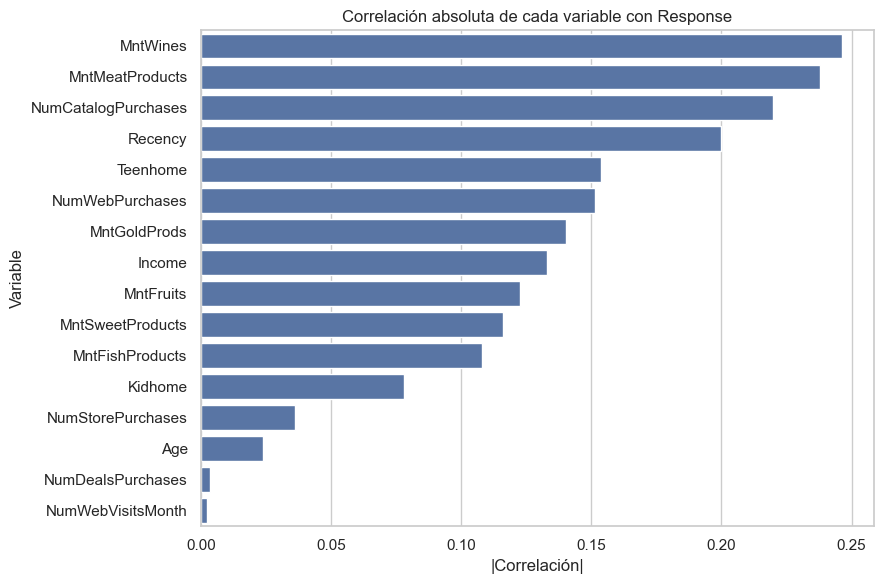

In [4]:
# Visualización de las correlaciones
plt.figure(figsize=(9, 6))
sns.barplot(x=correlaciones_abs.values, y=correlaciones_abs.index)
plt.title('Correlación absoluta de cada variable con Response')
plt.xlabel('|Correlación|')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

In [5]:
# Selección de las 8 variables con mayor correlación absoluta
seleccionadas = correlaciones_abs.head(8).index.tolist()
print('Variables seleccionadas:')
for v in seleccionadas:
    print(f'  - {v} (|corr| = {correlaciones_abs[v]:.3f})')

Variables seleccionadas:
  - MntWines (|corr| = 0.246)
  - MntMeatProducts (|corr| = 0.238)
  - NumCatalogPurchases (|corr| = 0.220)
  - Recency (|corr| = 0.200)
  - Teenhome (|corr| = 0.154)
  - NumWebPurchases (|corr| = 0.151)
  - MntGoldProds (|corr| = 0.140)
  - Income (|corr| = 0.133)


**Interpretación:**  
Las variables con mayor asociación con la respuesta a campañas son el gasto en vinos (`MntWines`) y en carnes (`MntMeatProducts`), las compras por catálogo (`NumCatalogPurchases`) y web (`NumWebPurchases`), la recencia (`Recency`), la cantidad de adolescentes en el hogar (`Teenhome`), el gasto en productos gold (`MntGoldProds`) y los ingresos (`Income`).

Este resultado es coherente con las hipótesis de la Parte I: el gasto en productos (H2), la actividad de compra online (H3) y los ingresos (H1) aparecen entre las variables más relevantes, mientras que la edad (`Age`, H4) queda descartada por su baja correlación, tal como anticipaba el análisis exploratorio. De esta forma se reduce la dimensionalidad de 16 variables candidatas a 8.

---
## 4. Entrenamiento del modelo: Regresión Logística

Se elige la **Regresión Logística**, algoritmo de clasificación visto en el curso, adecuado para este problema porque:

- La variable objetivo es **binaria** (aceptó / no aceptó la campaña).
- Estima la **probabilidad** de pertenencia a la clase positiva mediante la función sigmoide, con un umbral de 0,5 para clasificar.
- Es un modelo simple e interpretable (principio de parsimonia visto en el curso).

Siguiendo el criterio del material, se divide el dataset en **70% para entrenamiento y 30% para testing**. El modelo se evalúa sobre datos que nunca vio, porque no se puede ser "juez y parte" al mismo tiempo.

In [6]:
# Matriz de variables predictoras y variable objetivo
X = df[seleccionadas]
y = df['Response_num']

# División train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print('Datos de entrenamiento:', X_train.shape)
print('Datos de testing:', X_test.shape)

Datos de entrenamiento: (1551, 8)
Datos de testing: (665, 8)


In [7]:
# Ajuste del modelo
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

# Predicciones sobre el conjunto de test
predicciones = model.predict(X_test)

print('Modelo entrenado. Primeras 10 predicciones:', predicciones[:10])

Modelo entrenado. Primeras 10 predicciones: [0 0 0 0 0 1 0 0 0 0]


---
## 5. Validación del modelo: métricas básicas

### 5.1 Matriz de confusión

La matriz de confusión permite visualizar los aciertos y errores del clasificador:

- **Verdadero Negativo (VN):** predijo que no aceptaba y no aceptó.
- **Falso Positivo (FP):** predijo que aceptaba pero no aceptó.
- **Falso Negativo (FN):** predijo que no aceptaba pero aceptó.
- **Verdadero Positivo (VP):** predijo que aceptaba y aceptó.

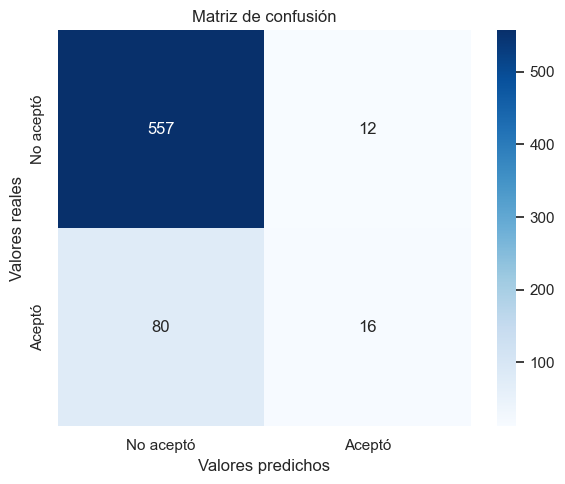

In [8]:
cf_matrix = confusion_matrix(y_test, predicciones)

plt.figure(figsize=(6, 5))
ax = sns.heatmap(cf_matrix, annot=True, fmt='d', cmap='Blues')
ax.set_title('Matriz de confusión')
ax.set_xlabel('Valores predichos')
ax.set_ylabel('Valores reales')
ax.xaxis.set_ticklabels(['No aceptó', 'Aceptó'])
ax.yaxis.set_ticklabels(['No aceptó', 'Aceptó'])
plt.tight_layout()
plt.show()

### 5.2 Métricas de clasificación

Se calculan las métricas vistas en el curso a partir de la matriz de confusión:

- **Exactitud (Accuracy):** (VP+VN) / (VP+FP+FN+VN) — porcentaje total de clasificaciones correctas.
- **Precisión:** VP / (VP+FP) — de los clientes que el modelo predijo como aceptantes, cuántos realmente aceptaron.
- **Sensibilidad (Recall):** VP / (VP+FN) — de los clientes que realmente aceptaron, cuántos detectó el modelo.
- **Especificidad:** VN / (VN+FP) — de los clientes que no aceptaron, cuántos identificó correctamente.
- **F1-Score:** 2 x (Precisión x Recall) / (Precisión + Recall) — resumen de precisión y sensibilidad en una sola métrica.

In [9]:
# Componentes de la matriz de confusion
vn = cf_matrix[0, 0]  # Verdaderos Negativos
fp = cf_matrix[0, 1]  # Falsos Positivos
fn = cf_matrix[1, 0]  # Falsos Negativos
vp = cf_matrix[1, 1]  # Verdaderos Positivos

print(f'Verdaderos Negativos (VN): {vn}')
print(f'Falsos Positivos (FP):     {fp}')
print(f'Falsos Negativos (FN):     {fn}')
print(f'Verdaderos Positivos (VP): {vp}')

# Calculo de metricas con las formulas vistas en el curso
exactitud = (vp + vn) / (vp + fp + fn + vn)
precision = vp / (vp + fp)
sensibilidad = vp / (vp + fn)
especificidad = vn / (vn + fp)
f1 = 2 * (sensibilidad * precision) / (sensibilidad + precision)

print()
print(f'Exactitud (Accuracy):   {exactitud:.3f}')
print(f'Precisión:              {precision:.3f}')
print(f'Sensibilidad (Recall):  {sensibilidad:.3f}')
print(f'Especificidad:          {especificidad:.3f}')
print(f'F1-Score:               {f1:.3f}')

# Verificacion de la exactitud con la funcion de sklearn vista en clase
print()
print(f'Verificación con accuracy_score: {accuracy_score(y_test, predicciones):.3f}')

Verdaderos Negativos (VN): 557
Falsos Positivos (FP):     12
Falsos Negativos (FN):     80
Verdaderos Positivos (VP): 16

Exactitud (Accuracy):   0.862
Precisión:              0.571
Sensibilidad (Recall):  0.167
Especificidad:          0.979
F1-Score:               0.258

Verificación con accuracy_score: 0.862


**Interpretación de las métricas:**

- La **exactitud del 86%** parece alta, pero debe leerse con cautela: como el 85% de los clientes no aceptó la campaña, un modelo trivial que siempre prediga "no acepta" alcanzaría una exactitud similar. Este es el efecto del desbalance de clases advertido en el material del curso.
- La **especificidad es muy alta (98%)**: el modelo identifica muy bien a los clientes que no aceptarán la campaña.
- La **sensibilidad es baja (17%)**: el modelo detecta pocos de los clientes que realmente aceptarían. Según las consideraciones del F1-Score vistas en el curso, estamos en el caso de *alta precisión relativa y bajo recall*: el modelo no detecta bien la clase positiva, pero cuando la predice es razonablemente confiable.
- El **F1-Score bajo (0,26)** refleja ese desequilibrio entre precisión y sensibilidad para la clase minoritaria.

### 5.3 Interpretación de los coeficientes del modelo

In [10]:
coeficientes = pd.DataFrame({
    'Variable': seleccionadas,
    'Coeficiente': model.coef_[0]
}).sort_values('Coeficiente', ascending=False)

coeficientes.round(5)

,Variable,Coeficiente
2,NumCatalogPurchases,0.16796
5,NumWebPurchases,0.11123
6,MntGoldProds,0.00182
0,MntWines,0.00131
1,MntMeatProducts,0.00115
7,Income,-0.00003
3,Recency,-0.02318
4,Teenhome,-0.69909


**Interpretación:**  
Los coeficientes positivos aumentan la probabilidad de aceptar la campaña y los negativos la disminuyen. Se observa que las compras por catálogo y web y el gasto en productos tienen efecto positivo, mientras que la recencia (más días desde la última compra) y la cantidad de adolescentes en el hogar tienen efecto negativo. Esto es coherente con el análisis exploratorio de la Parte I.

---
## 6. Conclusiones

A partir del trabajo realizado en esta entrega se concluye:

1. **Feature selection:** el método de filtrado por correlación permitió reducir la dimensionalidad de 16 variables candidatas a 8, confirmando los hallazgos de la Parte I: el gasto en productos, la actividad de compra (catálogo y web), la recencia y los ingresos son las variables más asociadas a la respuesta. La edad quedó descartada, en línea con lo anticipado por el análisis exploratorio.

2. **Modelo:** la Regresión Logística alcanzó una exactitud del 86% sobre el conjunto de test, con muy buena capacidad para identificar a los clientes que no aceptarán la campaña (especificidad del 98%).

3. **Limitación principal:** el desbalance de clases (85/15) hace que el modelo tenga baja sensibilidad (17%) para detectar a los clientes que sí aceptarían. En un contexto de negocio donde el objetivo es encontrar potenciales aceptantes, esta métrica es la más relevante y debe mejorarse.

4. **Próximos pasos:** para mejorar la detección de la clase positiva se podría: (a) ajustar el umbral de clasificación de la regresión logística, (b) aplicar técnicas de balanceo de clases, (c) probar otros algoritmos de clasificación vistos en el curso, como árboles de decisión o KNN, y comparar sus métricas.

En síntesis, el modelo constituye una primera aproximación válida al problema de predicción de respuesta a campañas: confirma cuáles son las variables relevantes y establece una línea base de métricas sobre la cual iterar en futuras etapas del proyecto.

---
**Nota sobre la entrega:** este notebook (`ProyectoParteIII+Massironi.ipynb`) y la base de datos (`Defaultoutput.xlsx`) se encuentran disponibles en el repositorio de GitHub del proyecto, según lo requerido por la consigna.